In [10]:
import copy
import os.path
from typing import TypedDict, Any, NamedTuple

import pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import numpy as np



from tool import crop_rgb
from paddleocr import PaddleOCR
ocr = PaddleOCR(

use_doc_orientation_classify=False,

use_doc_unwarping=False,

use_textline_orientation=False,

engine="paddle",
)

Creating model: ('PP-OCRv6_medium_det', None, 'paddle')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/trip/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, 'paddle')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/trip/.paddlex/official_models/PP-OCRv6_medium_rec`.


In [3]:
%store -r data_df

In [4]:
example_row = data_df[data_df["Name"]=="0000000009_d-582_0000020435-0001_log06_fe_5in_md"].iloc[0]

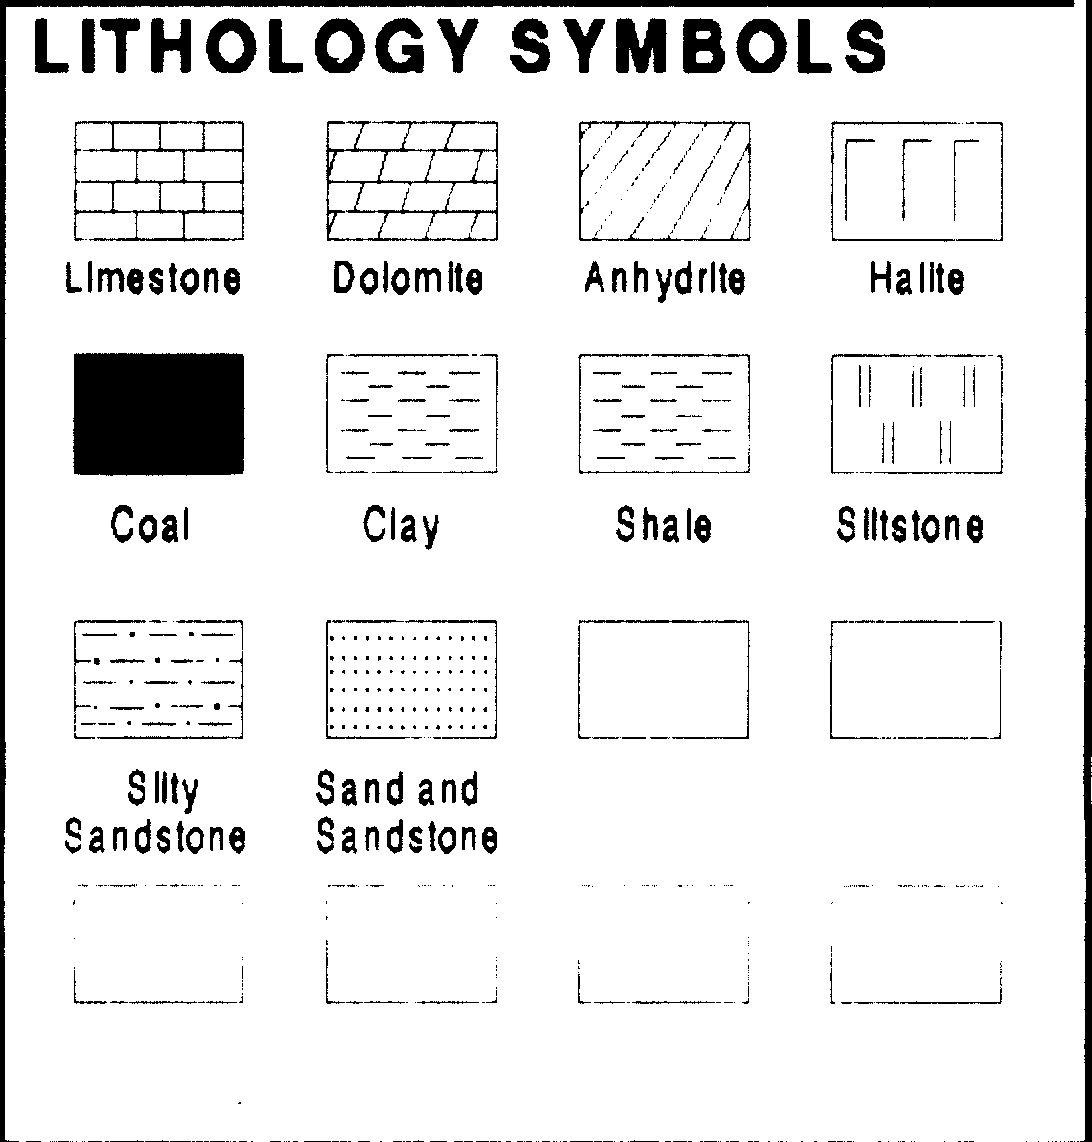

layout: sparse  (median vertical neighbour gap = 3.97 x text height)
'Limestone' (59, 253, 245, 300)
'Dolomite' (327, 252, 486, 301)
'Anhydrite' (578, 252, 750, 305)
'Halite' (862, 253, 970, 301)
'Coal' (102, 494, 198, 551)
'Clay' (352, 491, 449, 558)
'Shale' (606, 493, 719, 552)
'Slltstone' (830, 496, 989, 549)
'Sllty Sandstone' (57, 758, 249, 859)
'Sand and Sandstone' (309, 761, 502, 861)


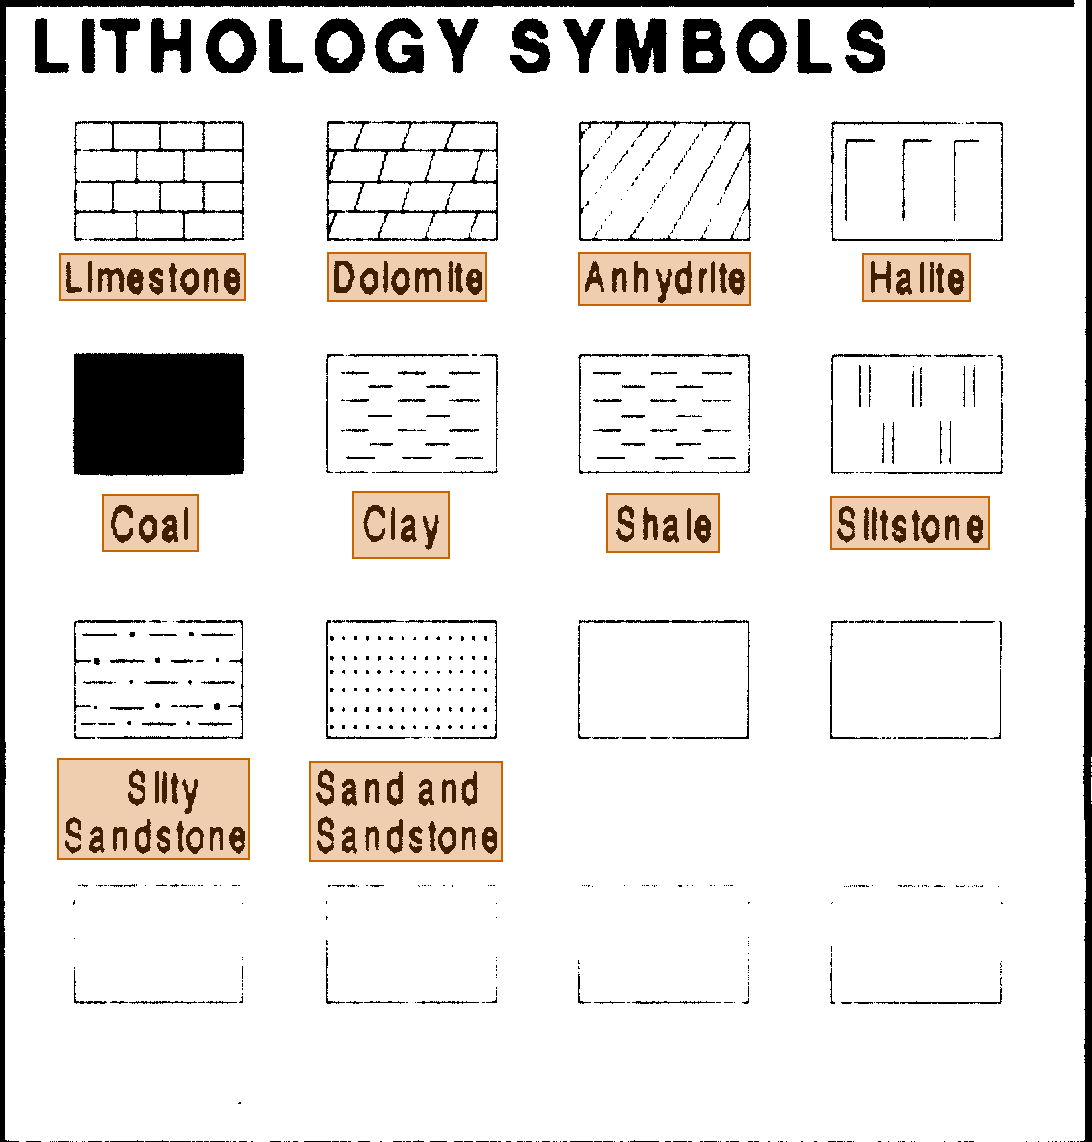

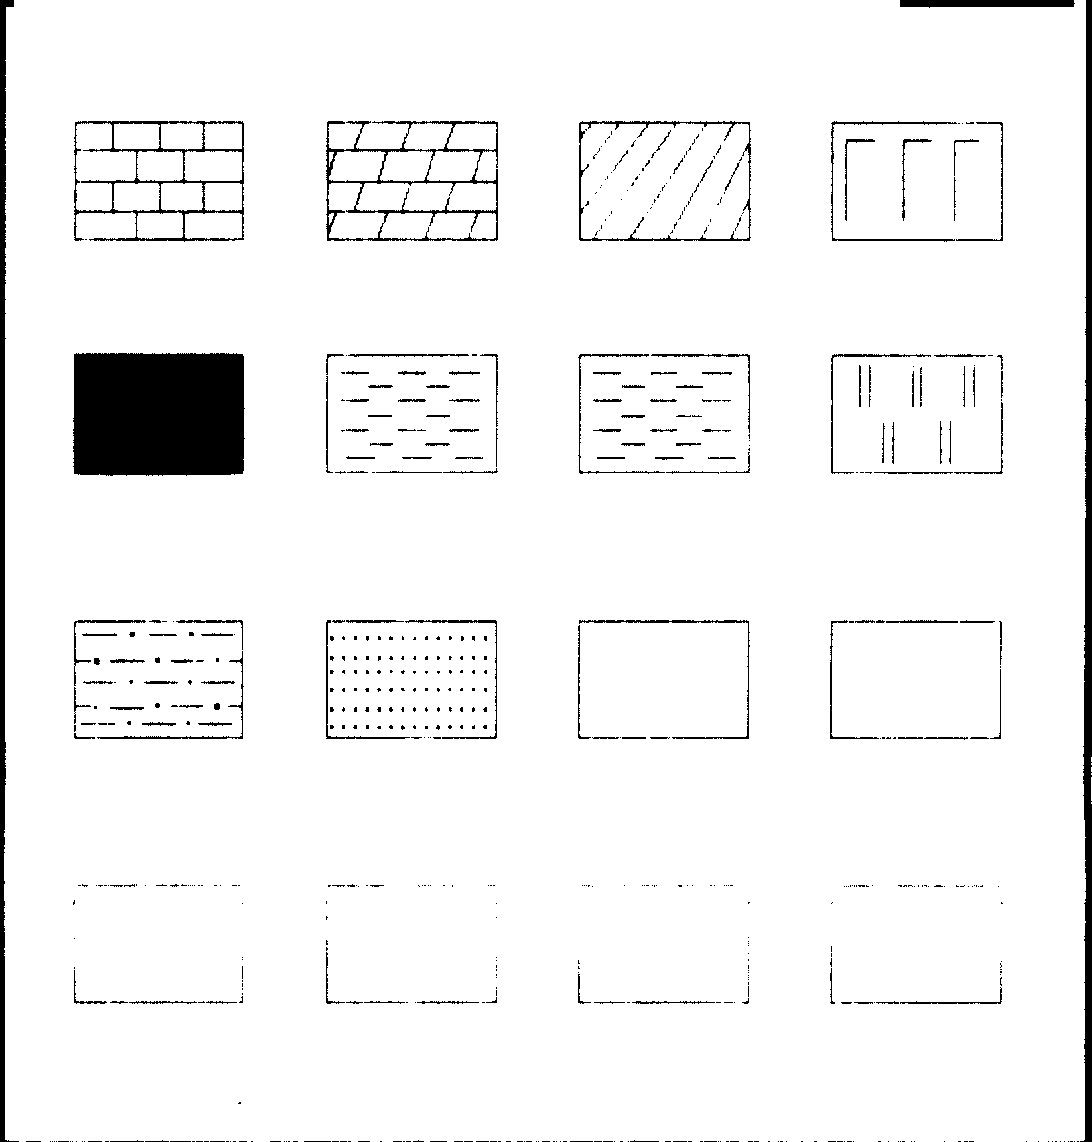

symbols are up of their labels   votes: {'up': 10}


{'Limestone': 'iVBORw0KGgoAAAANSUhEUgAAAK4AAAB8CAIAAAB/mBydAAAFA0lEQVR4nO2d25KsIAxF06fm/3/Z86BFcwmISpsd2OthakppCDGEgEY/27YJISL/rAUgKPyVhz6fz7Zt4W98qjzST/zbe/U8af02p43WCuzuNu5yfLZW52kxtdoetZTXNBw52vr+97qWCQLBAFoTxF5I/RvoaSYu3P5Jf+DSKDk2+ml0c0vJmlY1ppZRa24ciUWK/6lpuJQhJriA3Cu8E0XW3KYJCMJYyRBfdJuwEcECAj3u7QUZbAWQzBQQBCJWcDEpAhMy2w5FmgI5SEwBZHAsi63+GSuQA04Q5ICmAATDRgIRpdEUgAAKGxFsc016btD8Gq4ggIDwCvQHtiDon7ECBAj++DAFBFFWhl4BBfORABQ2IlilIYt3fyeZIKgRWyBWEDvmfnJZEAYhYwUIEAYhYwURgCvx5jPGNbiYFAEYCYaxWlceBHkNQ1sMTdvcjvqmYVgPR0mFQZDHilaiXG3WUEsm2XfPFGqSGzmQMjsRnGN6asxS3GxYhP1C55nU7Wy9QJnYFXuF2pHstzWZGrU1fM/pcbU2VYbTjO+abI2+dHrNRq9r+owLN1qXs7GdewV3SwmEZVgsiWAI04mSM+lIeli863CGLSbv1wCExCs41alrO8Zhhi0mKAuGEuYSM5gClFeAEuYSM5iC34EIxQymQIZAUyAHNIXB+J2taAqDcRc28nkFkjODKUANRE4QlkBpH8ouLzHDPQjyhPyBNqiBRUxIvIJT3+BUbBD0FYRT3+BUbDQ4QayO/vA7eY67QZVPEK5jBfIEfQXhzqIB8TucZpgg/GofihlMgc5sCDOYAr3CEGYwBSivACXMJXybAuDCB0qYS0zyjmcEyRFkeELuFXr6o76H4MkA/aR01padVQvHB2Oxn1y2UrZMIZfe02BlQKWQrcRk72ZOOrH85CgBpPV+heHBcHhDgPomg

In [9]:
import math
import os
import re
import tempfile
from collections import Counter
from statistics import median
from typing import NamedTuple
import base64
from io import BytesIO
from typing import TypedDict, Any, NamedTuple

import numpy as np
from PIL import Image, ImageDraw


DENSE_THRESHOLD = 1.0
HEADER_RATIO = 1.3
SPLIT_GAP = 0.45
SYMBOL_DENSITY = 0.55
COLOUR_FRAC = 0.5

PROFILES = {
    # why are we packing this tight bro
    "dense": dict(line_gap=0.6, min_v_overlap=0.8, allow_wrap=False),
    # big boys
    "sparse": dict(line_gap=0.8, min_v_overlap=0.6, allow_wrap=True,
                   wrap_gap=0.6, wrap_x_overlap=0.5),
}


class BoundingBox(NamedTuple):
    minX: float
    minY: float
    maxX: float
    maxY: float

    @property
    def w(self): return self.maxX - self.minX
    @property
    def h(self): return self.maxY - self.minY
    @property
    def cy(self): return (self.minY + self.maxY) / 2
### LOOKIE HERE HELPER FUNCTIONS ARE HERE


class BoundingBoxes(TypedDict): #### LOOKIE HERE I JUST STOLE THIS CLASS DEVINITON IT MAY NOT NEED TO BE HERE
    depth_column: BoundingBox
    interpreted_lithology_column: BoundingBox
    lithology_legend: BoundingBox
class Annotation(TypedDict):
    image_name: str
    width: int
    height: int
    bounding_boxs: BoundingBoxes

def legendBoxFromBoxes(boxes: BoundingBoxes):
    return boxes.lithology_legend

def tupleFromBox(box: BoundingBox):
    return (box.minX, box.minY, box.maxX, box.maxY)

#############################

def union(a: BoundingBox, b: BoundingBox) -> BoundingBox:
    return BoundingBox(min(a.minX, b.minX), min(a.minY, b.minY),
                       max(a.maxX, b.maxX), max(a.maxY, b.maxY))


def x_overlap(a, b):
    return min(a.maxX, b.maxX) - max(a.minX, b.minX)


def y_overlap(a, b):
    return min(a.maxY, b.maxY) - max(a.minY, b.minY)


def is_alpha_label(t: str) -> bool:
    return bool(t) and all(c.isalpha() or c == " " for c in t) and any(c.isalpha() for c in t)


# ---------------- OCR ----------------
def run_ocr(img: Image.Image, save_dir=None):
    out = []
    with tempfile.TemporaryDirectory() as d:
        path = os.path.join(d, "img.png")
        img.save(path)
        for r in ocr.predict(path):
            if save_dir:
                r.save_to_img(save_dir)
            res = r["res"] if "res" in r else r
            for text, b in zip(res["rec_texts"], res["rec_boxes"]):
                text = " ".join(text.split())
                if text:
                    out.append((text, BoundingBox(*map(float, b[:4]))))
    return out


def ocr_crop(img: Image.Image, box: BoundingBox, pad_ratio=0.6, scale=2) -> str:
    crop = img.crop((int(box.minX), int(box.minY), math.ceil(box.maxX), math.ceil(box.maxY)))
    pad = max(4, int(pad_ratio * box.h))
    canvas = Image.new("RGB", (crop.width + 2 * pad, crop.height + 2 * pad), (255, 255, 255))
    canvas.paste(crop, (pad, pad))
    canvas = canvas.resize((canvas.width * scale, canvas.height * scale), Image.LANCZOS)
    found = sorted(run_ocr(canvas), key=lambda tb: tb[1].minX)
    return " ".join(t for t, _ in found)


def ink_maps(arr):
    arr = arr.astype(np.float32)
    mx, mn = arr.max(axis=2), arr.min(axis=2)
    lum = arr @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    sat = (mx - mn) / (mx + 1e-6)
    colourful = (sat > 0.25) & (mx > 60)
    ink = (lum < 170) | colourful
    return ink, colourful


def trim_symbols(arr, box: BoundingBox):
    H, W = arr.shape[:2]
    x0, y0 = max(0, int(box.minX)), max(0, int(box.minY))
    x1, y1 = min(W, math.ceil(box.maxX)), min(H, math.ceil(box.maxY))
    if x1 - x0 < 2 or y1 - y0 < 2:
        return box, False

    ink, colourful = ink_maps(arr[y0:y1, x0:x1])
    ink_cols = ink.sum(axis=0)
    colour_cols = (ink & colourful).sum(axis=0)
    is_colour_col = (ink_cols > 0) & (colour_cols >= 0.5 * ink_cols)
    is_text_col = (ink_cols >= 2) & ~is_colour_col

    trimmed = False
    left, right = 0, len(ink_cols)
    while left < right and not is_text_col[left]:
        trimmed |= bool(is_colour_col[left])
        left += 1
    while right > left and not is_text_col[right - 1]:
        trimmed |= bool(is_colour_col[right - 1])
        right -= 1
    if left >= right:
        return (None if trimmed else box), trimmed

    h = y1 - y0
    xs = np.flatnonzero(is_text_col[left:right]) + left
    breaks = np.flatnonzero(np.diff(xs) > SPLIT_GAP * h)
    segs = [(int(s[0]), int(s[-1]) + 1) for s in np.split(xs, breaks + 1)]

    def is_symbol(s):
        m = ink[:, s[0]:s[1]]
        n_ink = m.sum()
        density = n_ink / m.size
        colour_frac = (m & colourful[:, s[0]:s[1]]).sum() / max(1, n_ink)
        return density > SYMBOL_DENSITY or colour_frac > COLOUR_FRAC

    while len(segs) > 1 and is_symbol(segs[0]):
        segs.pop(0)
        trimmed = True
    while len(segs) > 1 and is_symbol(segs[-1]):
        segs.pop()
        trimmed = True

    if not trimmed:
        return box, False
    return BoundingBox(x0 + segs[0][0], box.minY, x0 + segs[-1][1], box.maxY), True


def clean_fragments(img: Image.Image, items):
    arr = np.asarray(img.convert("RGB"))
    out = []
    for text, box in items:
        new_box, trimmed = trim_symbols(arr, box)
        if new_box is None:
            print(f"dropped symbol-only fragment {text!r}")
            continue
        if trimmed:
            new_text = ocr_crop(img, new_box) or re.sub(r"^[^A-Za-z]+|[^A-Za-z]+$", "", text)
            new_text = " ".join(new_text.split())
            print(f"trimmed symbol: {text!r} -> {new_text!r}")
            text, box = new_text, new_box
        out.append((text, box))
    return out

def vertical_neighbour_gaps(boxes):
    gaps = []
    for i, a in enumerate(boxes):
        best = float("inf")
        for j, b in enumerate(boxes):
            if i == j or x_overlap(a, b) < 0.3 * min(a.w, b.w):
                continue
            gap = -y_overlap(a, b)
            if gap < 0:
                continue
            best = min(best, gap / min(a.h, b.h))
        gaps.append(best)
    return gaps


def detect_layout(boxes):
    if len(boxes) < 3:
        return "dense", float("nan")
    g = median(vertical_neighbour_gaps(boxes))
    return ("dense" if g < DENSE_THRESHOLD else "sparse"), g


def drop_headers(items):
    if len(items) < 3:
        return items
    med_h = median(b.h for _, b in items)
    return [(t, b) for t, b in items if b.h <= HEADER_RATIO * med_h]


def should_merge(a: BoundingBox, b: BoundingBox, line_gap, min_v_overlap,
                 allow_wrap=False, wrap_gap=0.0, wrap_x_overlap=1.0):
    h = min(a.h, b.h)
    if h <= 0 or max(a.h, b.h) > 1.4 * h:
        return False
    if y_overlap(a, b) >= min_v_overlap * h and -x_overlap(a, b) <= line_gap * h:
        return True
    if allow_wrap and x_overlap(a, b) >= wrap_x_overlap * min(a.w, b.w) and -y_overlap(a, b) <= wrap_gap * h:
        return True
    return False


def reading_order_text(group):
    group = sorted(group, key=lambda tb: tb[1].cy)
    lines = []
    for t, b in group:
        if lines and abs(b.cy - lines[-1][-1][1].cy) < 0.5 * min(b.h, lines[-1][-1][1].h):
            lines[-1].append((t, b))
        else:
            lines.append([(t, b)])
    return " ".join(t for line in lines for t, _ in sorted(line, key=lambda tb: tb[1].minX))


def merge_fragments(items, profile):
    n = len(items)
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i


    for i in range(n):
        for j in range(i + 1, n):
            if should_merge(items[i][1], items[j][1], **profile):
                parent[find(i)] = find(j)

    groups = {}
    for i, item in enumerate(items):
        groups.setdefault(find(i), []).append(item)

    merged = []
    for g in groups.values():
        box = g[0][1]
        for _, b in g[1:]:
            box = union(box, b)
        merged.append((reading_order_text(g), box))
    return merged


def draw_boxes(img: Image.Image, boxes, color=(200, 100, 0)) -> Image.Image:
    overlay = Image.new("RGBA", img.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)
    for b in boxes:
        draw.rectangle((b.minX, b.minY, b.maxX, b.maxY),
                       fill=(*color, 80), outline=(*color, 255), width=2)
    return Image.alpha_composite(img.convert("RGBA"), overlay)



def background_colour(img: Image.Image):
    arr = np.asarray(img.convert("RGB")).reshape(-1, 3)
    return tuple(int(v) for v in np.median(arr, axis=0))


def white_out_text(img: Image.Image, boxes, pad_ratio=0.12) -> Image.Image:
    masked = img.convert("RGB").copy()
    draw = ImageDraw.Draw(masked)
    bg = background_colour(img)
    for b in boxes:
        p = pad_ratio * b.h
        draw.rectangle((b.minX - p, b.minY - p, b.maxX + p, b.maxY + p), fill=bg)
    return masked

# logic is genuinely straight copy paste from stackoverflow
def nearest_ink(ink, box: BoundingBox, direction, band_shrink=0.15, max_reach=20, min_ink=2):
    H, W = ink.shape
    reach = int(max_reach * box.h)
    sx, sy = band_shrink * box.w, band_shrink * box.h
    bx0, bx1 = max(0, int(box.minX + sx)), min(W, math.ceil(box.maxX - sx))
    by0, by1 = max(0, int(box.minY + sy)), min(H, math.ceil(box.maxY - sy))
    x0, x1 = max(0, int(box.minX)), min(W, math.ceil(box.maxX))
    y0, y1 = max(0, int(box.minY)), min(H, math.ceil(box.maxY))
    if bx1 <= bx0 or by1 <= by0:
        return float("inf")

    if direction == "left":
        start = max(0, x0 - reach)
        hits = np.flatnonzero(ink[by0:by1, start:x0].sum(axis=0) >= min_ink)
        return float(x0 - (start + hits[-1])) if hits.size else float("inf")
    if direction == "right":
        hits = np.flatnonzero(ink[by0:by1, x1:min(W, x1 + reach)].sum(axis=0) >= min_ink)
        return float(hits[0] + 1) if hits.size else float("inf")
    if direction == "up":
        start = max(0, y0 - reach)
        hits = np.flatnonzero(ink[start:y0, bx0:bx1].sum(axis=1) >= min_ink)
        return float(y0 - (start + hits[-1])) if hits.size else float("inf")
    if direction == "down":
        hits = np.flatnonzero(ink[y1:min(H, y1 + reach), bx0:bx1].sum(axis=1) >= min_ink)
        return float(hits[0] + 1) if hits.size else float("inf")
    raise ValueError(direction)


def vote_symbol_direction(masked: Image.Image, labels, **kw):
    ink, _ = ink_maps(np.asarray(masked.convert("RGB")))
    votes = Counter()
    per_label = []
    for text, box in labels:
        dists = {d: nearest_ink(ink, box, d, **kw) for d in ("left", "right", "up", "down")}
        best = min(dists, key=dists.get)
        if dists[best] < float("inf"):
            votes[best] += 1
        per_label.append((text, dists))
    direction = votes.most_common(1)[0][0] if votes else None
    return direction, votes, per_label


def pil_to_base64(img: Image.Image, fmt: str = "PNG") -> str:
    buf = BytesIO()
    img.save(buf, format=fmt)
    return base64.b64encode(buf.getvalue()).decode("utf-8")

def get_symbols(img, masked, labels, direction, text_h=None,
                gap_ratio=1.0, side_gap_ratio=0.5, pad=2):
    ink, _ = ink_maps(np.asarray(masked.convert("RGB")))
    H, W = ink.shape
    symbols = {}


    if text_h is None:
        text_h = median(b.h for _, b in labels)
    h = max(1, int(text_h))
    gap = int(gap_ratio * h)
    side_gap = int(side_gap_ratio * h)
    max_walk = 20 * h

    def col_has_ink(x, y0, y1):
        if x < 0 or x >= W:
            return False
        return ink[max(0, y0):min(H, y1), x].sum() >= 2

    def row_has_ink(y, x0, x1):
        if y < 0 or y >= H:
            return False
        return ink[y, max(0, x0):min(W, x1)].sum() >= 2

    for text, box in labels:
        x0, y0, x1, y1 = int(box.minX), int(box.minY), int(box.maxX), int(box.maxY)

        if direction == "left" or direction == "right":
            step = -1 if direction == "left" else 1
            x = x0 - 1 if direction == "left" else x1 + 1


            walked = 0
            while 0 <= x < W and walked < max_walk and not col_has_ink(x, y0, y1):
                x += step
                walked += 1
            if not (0 <= x < W) or walked >= max_walk:
                print("no symbol found for", text)
                continue
            near = x


            far = x
            empty = 0
            while 0 <= x < W and empty <= gap:
                if col_has_ink(x, y0, y1):
                    far = x
                    empty = 0
                else:
                    empty += 1
                x += step
            sx0, sx1 = min(near, far), max(near, far) + 1


            sy0, sy1 = y0, y1
            while sy0 > 0 and sy0 > y0 - h and row_has_ink(sy0 - 1, sx0, sx1):
                sy0 -= 1
            while sy1 < H and sy1 < y1 + h and row_has_ink(sy1, sx0, sx1):
                sy1 += 1

        else:
            step = -1 if direction == "up" else 1
            y = y0 - 1 if direction == "up" else y1 + 1


            walked = 0
            while 0 <= y < H and walked < max_walk and not row_has_ink(y, x0, x1):
                y += step
                walked += 1
            if not (0 <= y < H) or walked >= max_walk:
                print("no symbol found for", text)
                continue
            near = y


            far = y
            empty = 0
            while 0 <= y < H and empty <= gap:
                if row_has_ink(y, x0, x1):
                    far = y
                    empty = 0
                else:
                    empty += 1
                y += step
            sy0, sy1 = min(near, far), max(near, far) + 1


            sx0 = x0
            x = x0
            empty = 0
            while x > 0 and empty <= side_gap:
                x -= 1
                if col_has_ink(x, sy0, sy1):
                    sx0 = x
                    empty = 0
                else:
                    empty += 1
            sx1 = x1
            x = x1
            empty = 0
            while x < W - 1 and empty <= side_gap:
                x += 1
                if col_has_ink(x, sy0, sy1):
                    sx1 = x + 1
                    empty = 0
                else:
                    empty += 1


        while sy0 < sy1 - 1 and not row_has_ink(sy0, sx0, sx1):
            sy0 += 1
        while sy1 - 1 > sy0 and not row_has_ink(sy1 - 1, sx0, sx1):
            sy1 -= 1
        while sx0 < sx1 - 1 and not col_has_ink(sx0, sy0, sy1):
            sx0 += 1
        while sx1 - 1 > sx0 and not col_has_ink(sx1 - 1, sy0, sy1):
            sx1 -= 1


        crop_box = (max(0, sx0 - pad), max(0, sy0 - pad), min(W, sx1 + pad), min(H, sy1 + pad))
        symbols[text] = img.crop(crop_box)

    return symbols

def doThing(data: Annotation, image):
    im = image
    boundthing = tupleFromBox(legendBoxFromBoxes(data.bounding_boxs))
    sym = crop_rgb(im, boundthing)


    raw = run_ocr(sym, save_dir="output")

    cleaned = clean_fragments(sym, raw)
    items = [(t, b) for t, b in cleaned if is_alpha_label(t)]
    items = drop_headers(items)

    layout, gap_stat = detect_layout([b for _, b in items])
    print(f"layout: {layout}  (median vertical neighbour gap = {gap_stat:.2f} x text height)")

    labels = merge_fragments(items, PROFILES[layout])
    labels = [(t, b) for t, b in labels if len(t.replace(" ", "")) > 2]

    for t, b in labels:
        print(repr(t), tuple(round(v) for v in b))

    finalBoxes = [b for _, b in labels]


    text_boxes = [b for t, b in cleaned if any(c.isalpha() for c in t)]
    masked = white_out_text(sym, text_boxes)

    direction, votes, per_label = vote_symbol_direction(masked, labels)
    print(f"symbols are {direction} of their labels   votes: {dict(votes)}")

    text_h = median(b.h for _, b in items)
    final_data = get_symbols(sym, masked, labels, direction, text_h=text_h)
    return final_data


In [6]:
len(finalBoxes)

10